# 04 — Tuned forecasting evaluation

Compare three models and a weekly baseline on all 30,490 series. Settings use development windows only; the local test is retrospective.

## Imports

In [1]:
from pathlib import Path
from types import SimpleNamespace
import os, json, time, warnings
import numpy as np
import pandas as pd
from IPython.display import display


In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/calendar.csv').exists())
DATA = ROOT / 'data'
OUT = DATA / 'processed'
RESULTS = ROOT / 'reports/results'
FIGURES = ROOT / 'reports/figures'
for folder in [OUT, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.venv/matplotlib'))


'/Users/moha/Machine-Learning-Project/Project 1/.venv/matplotlib'

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':100, 'axes.spines.top':False, 'axes.spines.right':False})
COLORS = ['#2563eb', '#059669', '#ea580c', '#7c3aed']


## Load prepared arrays

In [4]:
sales = np.load(OUT / 'sales.npy', mmap_mode='r')
prices = np.load(OUT / 'prices.npy', mmap_mode='r')
metadata = pd.read_csv(OUT / 'metadata.csv')
calendar = pd.read_csv(OUT / 'calendar.csv', parse_dates=['date'])
config = json.loads((ROOT / 'configs/comparison.json').read_text())
data = SimpleNamespace(root=ROOT)


In [5]:
def save_figure(data, name):
    plt.gcf().tight_layout()
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()


## Load the comparison results

In [6]:
import hashlib
scores=pd.read_csv(RESULTS / 'tuned_scores.csv')
panel=pd.read_csv(OUT / 'comparison_series.csv')
diagnostics=pd.read_csv(DATA / 'interim/tuned_fit_diagnostics.csv')
manifest=json.loads((RESULTS / 'tuned_manifest.json').read_text())
assert manifest['config']==config and manifest['series_count']==len(metadata)==30490
assert manifest['identity']['settings']==json.loads((ROOT / 'configs/tuning.json').read_text())
panel_rows=panel.row.to_numpy()
assert panel_rows.tolist()==list(range(len(metadata)))
assert panel.series_id.tolist()==metadata.series_id.tolist()
assert manifest['series_ids_hash']==hashlib.sha256('|'.join(panel.series_id).encode()).hexdigest()
assert set(scores.all_series)=={len(metadata)}
MODEL_NAMES=['ARIMA','SARIMA','LightGBM','SeasonalNaive']


In [7]:
confirmation=pd.read_csv(RESULTS / 'tuning_confirmation_scores.csv')
validation=confirmation.groupby(['family','candidate']).mean_rmsse.mean()
group_scores=pd.read_csv(RESULTS / 'tuning_group_scores.csv')
group_validation=group_scores.groupby(['family','demand_group','candidate']).mean_rmsse.mean()
selected=manifest['selected']
for family in ['ARIMA','SARIMA']:
    for group,specification in selected[family].items():
        assert group_validation.loc[(family,group)].idxmin()==specification['id']
assert manifest['test_used_for_selection'] is False
assert manifest['selection_cutoffs']==config['development_cutoffs']
assert config['test_cutoff'] not in set(confirmation.cutoff)|set(group_scores.cutoff)
assert set(confirmation.all_series)=={30490}
original_scores=pd.read_csv(RESULTS / 'full_panel_scores.csv')


In [8]:
series_settings=pd.read_csv(OUT / 'tuned_series_settings.csv')
assert series_settings.row.tolist()==panel_rows.tolist()
assert series_settings.series_id.tolist()==panel.series_id.tolist()
origin=min(config['development_cutoffs'])
frequency=(sales[panel_rows,origin-90:origin]>0).mean(axis=1)
regular=frequency>=manifest['identity']['settings']['regular_sales_rate']
assert series_settings.demand_group.tolist()==np.where(regular,'regular','intermittent').tolist()
for family in ['ARIMA','SARIMA']:
    expected=series_settings.demand_group.map(lambda group:selected[family][group]['id'])
    assert series_settings[family].tolist()==expected.tolist()
print('Group labels use only pre-development history; every series has frozen settings.')


Group labels use only pre-development history; every series has frozen settings.


## Comparable error metrics

In [9]:
def rmsse_scales(history):
    scales=[]
    for values in history:
        active=np.flatnonzero(values)
        differences=np.diff(values[active[0]:].astype('float64')) if len(active) else []
        scales.append(float(np.mean(np.square(differences))) if len(differences) else 0.)
    return np.asarray(scales)


In [10]:
def score_forecast(prediction, actual, scales):
    assert prediction.shape==actual.shape and np.isfinite(prediction).all()
    assert (prediction>=0).all()
    error=prediction.astype('float64')-actual
    valid=scales>0
    rmsse=np.sqrt(np.mean(error[valid]**2,axis=1)/scales[valid])
    return dict(mae=float(np.abs(error).mean()),rmse=float(np.sqrt(np.mean(error**2))),
                mean_rmsse=float(rmsse.mean()),rmsse_series=int(valid.sum()),
                all_series=len(actual))


## Recalculate every score from saved predictions

In [11]:
for result in scores.itertuples():
    prediction=np.load(DATA / f'interim/tuned_{result.model}_d{result.cutoff}.npy')
    actual=sales[panel_rows,result.cutoff:result.cutoff+28]
    scales=rmsse_scales(sales[panel_rows,:result.cutoff])
    recalculated=score_forecast(prediction,actual,scales)
    for metric,value in recalculated.items():
        assert np.isclose(value,getattr(result,metric))
print('All models use identical series, targets, horizons, and RMSSE scales.')


All models use identical series, targets, horizons, and RMSSE scales.


## Three models and the weekly baseline

In [12]:
development=scores[scores.phase=='development'].groupby('model').mean_rmsse.mean()
test=scores[scores.phase=='local_test'].set_index('model')
comparison=test[['mean_rmsse','mae','rmse']].rename(columns={
    'mean_rmsse':'test_rmsse','mae':'test_mae','rmse':'test_rmse'})
comparison.insert(0,'development_rmsse',development)
comparison=comparison.sort_values('development_rmsse')
comparison.to_csv(RESULTS / 'tuned_comparison.csv')
display(comparison)


,development_rmsse,test_rmsse,test_mae,test_rmse
model,,,,
SARIMA,0.735332,0.760355,1.049055,2.199251
ARIMA,0.735995,0.761730,1.056983,2.218067
LightGBM,0.737724,0.759525,1.047335,2.153174
SeasonalNaive,0.967113,0.997242,1.243972,2.676895


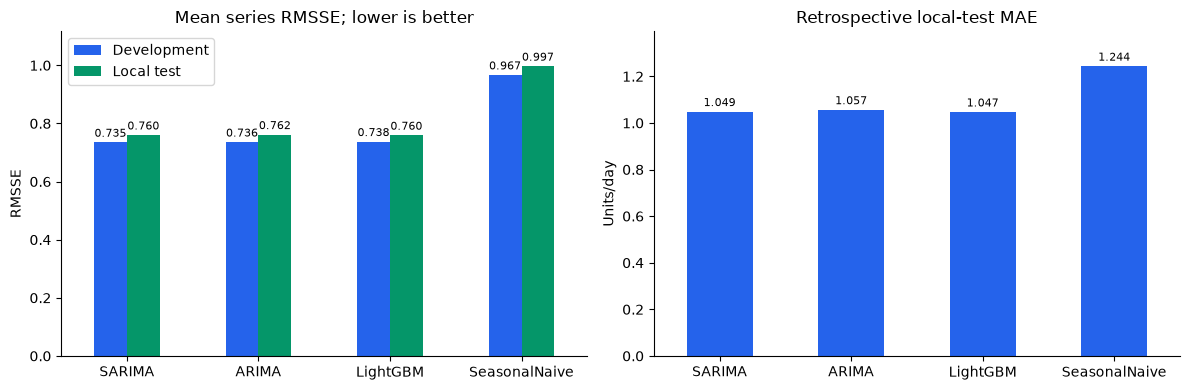

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
comparison[['development_rmsse','test_rmsse']].rename(columns={
    'development_rmsse':'Development','test_rmsse':'Local test'}).plot.bar(ax=axes[0],color=COLORS[:2])
axes[0].set(title='Mean series RMSSE; lower is better',xlabel='',ylabel='RMSSE')
comparison.test_mae.plot.bar(ax=axes[1],color=COLORS[0])
axes[1].set(title='Retrospective local-test MAE',xlabel='',ylabel='Units/day')
for ax in axes:
    ax.tick_params(axis='x',rotation=0)
    for container in ax.containers:
        ax.bar_label(container,fmt='%.3f',fontsize=8,padding=2)
    ax.margins(y=0.12)
save_figure(data,'comparison_01_models')


## Tuning against the original statistical settings

In [14]:
before=original_scores.query('phase=="local_test"').set_index('model')
improvement=comparison.loc[['ARIMA','SARIMA'],['test_rmsse','test_mae','test_rmse']].copy()
for metric,original_metric in [('rmsse','mean_rmsse'),('mae','mae'),('rmse','rmse')]:
    improvement[f'original_{metric}']=before.loc[improvement.index,original_metric]
    improvement[f'{metric}_improvement_pct']=100*(1-improvement[f'test_{metric}']/improvement[f'original_{metric}'])
improvement.to_csv(RESULTS / 'tuning_improvement.csv')
display(improvement.round(4))


,test_rmsse,test_mae,test_rmse,original_rmsse,rmsse_improvement_pct,original_mae,mae_improvement_pct,original_rmse,rmse_improvement_pct
model,,,,,,,,,
ARIMA,0.7617,1.0570,2.2181,0.7617,0.000,1.0570,0.0000,2.2181,0.0000
SARIMA,0.7604,1.0491,2.1993,0.7613,0.129,1.0538,0.4538,2.2030,0.1706


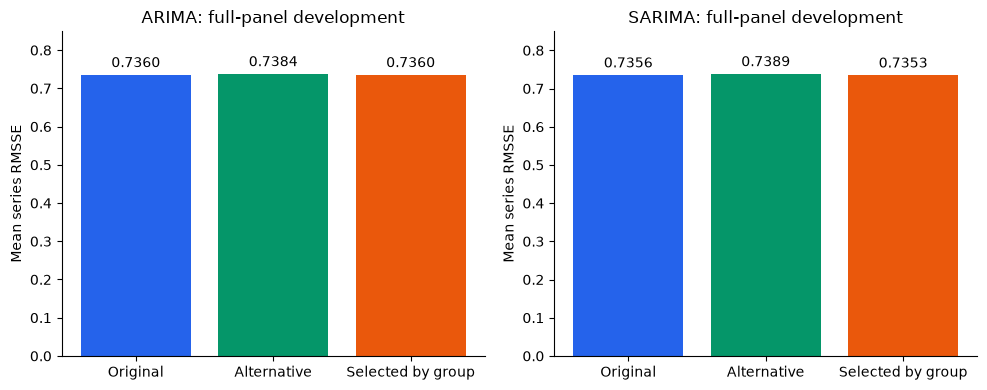

In [15]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,family in zip(axes,['ARIMA','SARIMA']):
    values=validation.loc[family]
    original=family.lower()+'_original'
    alternative=values.index[values.index!=original][0]
    bars=ax.bar(['Original','Alternative','Selected by group'],
        [values[original],values[alternative],comparison.loc[family,'development_rmsse']],color=COLORS[:3])
    ax.bar_label(bars,fmt='%.4f',padding=3)
    ax.set(title=f"{family}: full-panel development",ylabel='Mean series RMSSE')
    ax.margins(y=0.15)
save_figure(data,'comparison_05_tuning')


## Statistical fit diagnostics

In [16]:
optimized=diagnostics.status.ne('constant')
details=diagnostics.assign(optimized=optimized,converged_fit=optimized & diagnostics.converged,
                           constant=diagnostics.status.eq('constant'),
                           initialization_retry=diagnostics.status.isin(['diffuse_retry','optimizer_retry']))
convergence=details.groupby('model').agg(
    series_windows=('row','size'),optimized=('optimized','sum'),
    converged=('converged_fit','sum'),constant=('constant','sum'),
    initialization_retries=('initialization_retry','sum'),
    warnings=('warnings','sum'),negative_raw_forecasts=('negative_raw_forecasts','sum'))
convergence.to_csv(RESULTS / 'tuned_fit_summary.csv')
display(convergence)
print('Constant histories receive exact constant forecasts; all series are included.')
print('Finite nonconverged fits remain explicitly flagged; negative forecasts are clipped to zero.')


,series_windows,optimized,converged,constant,initialization_retries,warnings,negative_raw_forecasts
model,,,,,,,
ARIMA,91470,91380,91325,90,1,308,115
SARIMA,91470,91380,91344,90,1,209,3954


Constant histories receive exact constant forecasts; all series are included.
Finite nonconverged fits remain explicitly flagged; negative forecasts are clipped to zero.


## Error by forecast day

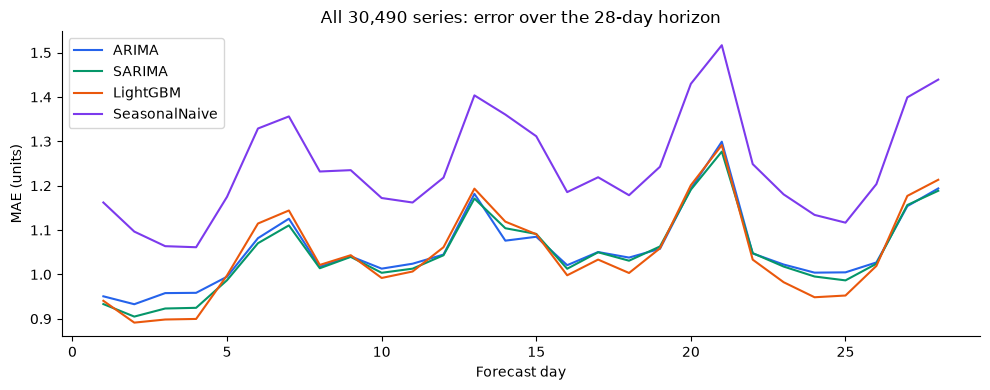

In [17]:
cutoff=config['test_cutoff']
actual=sales[panel_rows,cutoff:cutoff+28]
predictions={name:np.load(DATA / f'interim/tuned_{name}_d{cutoff}.npy')
             for name in MODEL_NAMES}
horizon=pd.DataFrame({name:np.abs(values-actual).mean(axis=0)
                      for name,values in predictions.items()},index=np.arange(1,29))
horizon.plot(figsize=(10,4),color=COLORS)
plt.xlabel('Forecast day'); plt.ylabel('MAE (units)')
plt.title('All 30,490 series: error over the 28-day horizon')
horizon.to_csv(RESULTS / 'tuned_horizon_errors.csv',index_label='forecast_day')
save_figure(data,'comparison_02_horizon')


## Frequent sellers and forecast failure cases

Frequent sellers have positive sales on at least 95% of 90 training days before the first development window.
Choose the median-volume eligible series per category; retain the earlier examples to document failures.

In [18]:
selection_end=min(config['development_cutoffs'])
selection_history=sales[panel_rows,selection_end-90:selection_end]
selling_rate=(selection_history>0).mean(axis=1)
selection_mean=selection_history.mean(axis=1)
eligible=selling_rate>=0.95
frequent_examples=[]
for category in ['HOBBIES','HOUSEHOLD','FOODS']:
    candidates=np.flatnonzero(eligible & panel.cat_id.eq(category).to_numpy())
    ranked=candidates[np.argsort(selection_mean[candidates],kind='stable')]
    frequent_examples.append(int(ranked[len(ranked)//2]))
print(f'{eligible.sum():,} series sold on at least 95% of the preceding 90 days.')
display(panel.iloc[frequent_examples][['series_id','cat_id']].assign(
    selling_days=(selection_history[frequent_examples]>0).sum(axis=1),
    mean_units=selection_mean[frequent_examples]))


897 series sold on at least 95% of the preceding 90 days.


,series_id,cat_id,selling_days,mean_units
6346,HOBBIES_1_256_CA_3,HOBBIES,86,7.855556
28443,HOUSEHOLD_1_447_WI_3,HOUSEHOLD,89,6.600000
19989,FOODS_1_085_TX_3,FOODS,87,7.800000


In [19]:
ordered=panel.mean_training_sales.sort_values().index
examples=[ordered[0],ordered[len(ordered)//2],ordered[-1]]


In [20]:
example_records=[]
for position in dict.fromkeys([*frequent_examples,*examples]):
    history=sales[panel_rows[position],cutoff-728:cutoff].astype('float64')
    for name,values in predictions.items():
        errors=values[position]-actual[position].astype('float64')
        example_records.append(dict(series=panel.series_id.iloc[position],model=name,
            training_mean_728=history.mean(),training_mean_56=history[-56:].mean(),
            actual_mean=actual[position].mean(),forecast_mean=values[position].mean(),
            mae=np.abs(errors).mean(),rmse=np.sqrt(np.mean(errors**2))))
example_errors=pd.DataFrame(example_records)
display(example_errors.round(3))


,series,model,training_mean_728,training_mean_56,actual_mean,forecast_mean,mae,rmse
0,HOBBIES_1_256_CA_3,ARIMA,5.764,4.821,2.893,5.589000,3.624,4.159
1,HOBBIES_1_256_CA_3,SARIMA,5.764,4.821,2.893,5.095000,3.150,3.713
2,HOBBIES_1_256_CA_3,LightGBM,5.764,4.821,2.893,4.350000,3.153,3.646
3,HOBBIES_1_256_CA_3,SeasonalNaive,5.764,4.821,2.893,4.143000,4.679,5.913
4,HOUSEHOLD_1_447_WI_3,ARIMA,7.143,6.196,7.214,6.242000,3.162,4.244
5,HOUSEHOLD_1_447_WI_3,SARIMA,7.143,6.196,7.214,6.216000,3.012,4.213
6,HOUSEHOLD_1_447_WI_3,LightGBM,7.143,6.196,7.214,5.990000,3.172,4.269
7,HOUSEHOLD_1_447_WI_3,SeasonalNaive,7.143,6.196,7.214,6.143000,4.500,5.372
8,FOODS_1_085_TX_3,ARIMA,6.022,8.964,11.464,9.643000,3.926,5.187
9,FOODS_1_085_TX_3,SARIMA,6.022,8.964,11.464,10.013000,3.732,4.922


In [21]:
import matplotlib.dates as mdates

def plot_example(ax,position):
    dates=calendar.date.iloc[cutoff:cutoff+28]
    history_dates=calendar.date.iloc[cutoff-56:cutoff]
    ax.plot(history_dates,sales[panel_rows[position],cutoff-56:cutoff],
            color='0.6',label='Observed history')
    ax.plot(dates,actual[position],color='black',label='Actual')
    errors=example_errors[example_errors.series.eq(panel.series_id.iloc[position])].set_index('model')
    for name,color in zip(MODEL_NAMES,COLORS):
        ax.plot(dates,predictions[name][position],color=color,
                label=f'{name} (MAE {errors.loc[name,"mae"]:.2f})')
    ax.axvline(dates.iloc[0],color='0.4',ls='--',lw=1)
    ax.set(title=panel.series_id.iloc[position],ylabel='Units/day')
    ax.legend(ncol=3,fontsize=7,loc='upper left')


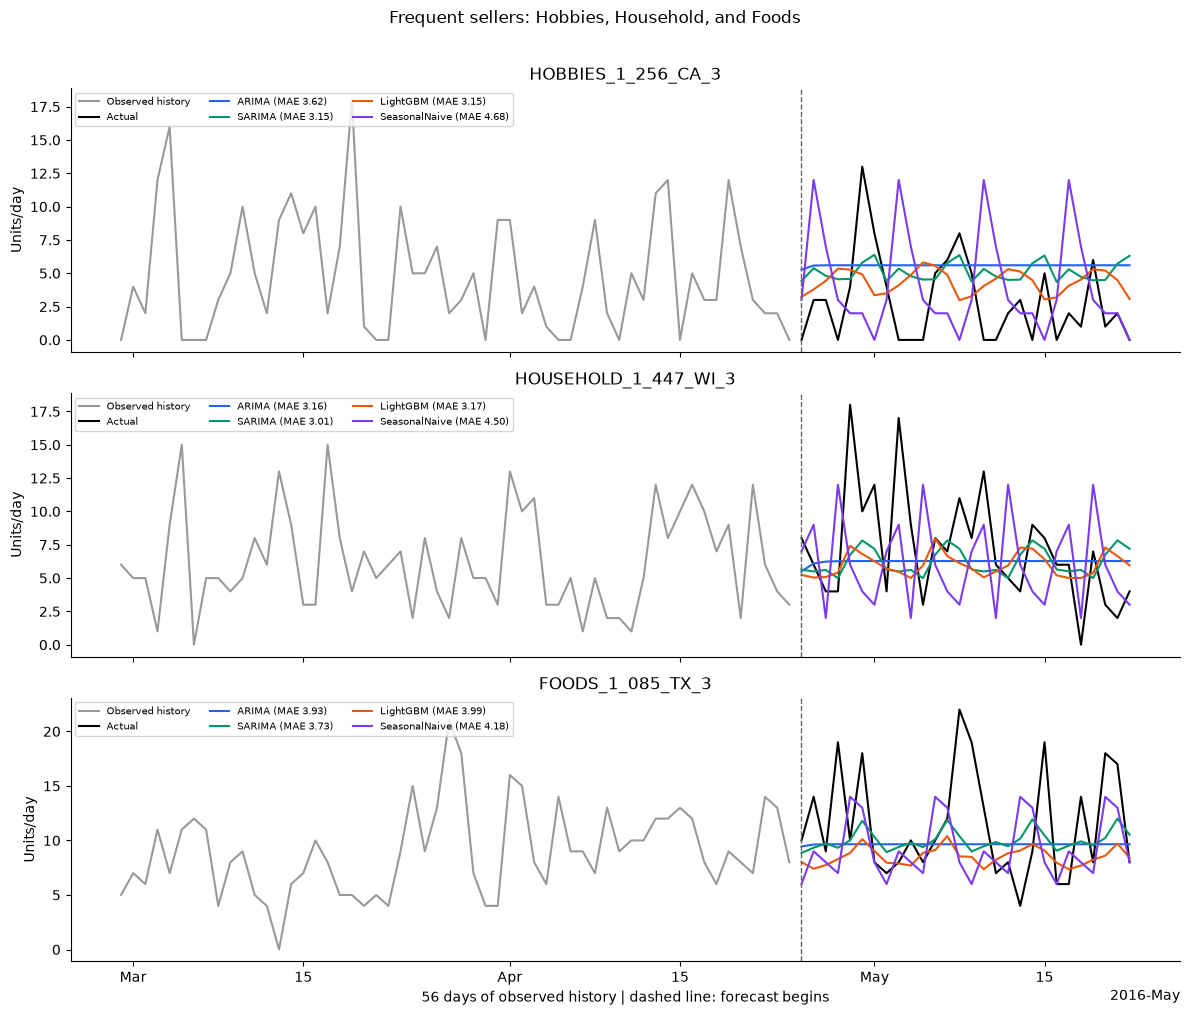

In [22]:
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True)
for ax,position in zip(axes,frequent_examples):
    plot_example(ax,position)
locator=mdates.AutoDateLocator(minticks=5,maxticks=8)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[-1].set_xlabel('56 days of observed history | dashed line: forecast begins')
fig.suptitle('Frequent sellers: Hobbies, Household, and Foods',y=1.01)
save_figure(data,'comparison_04_frequent_sellers')


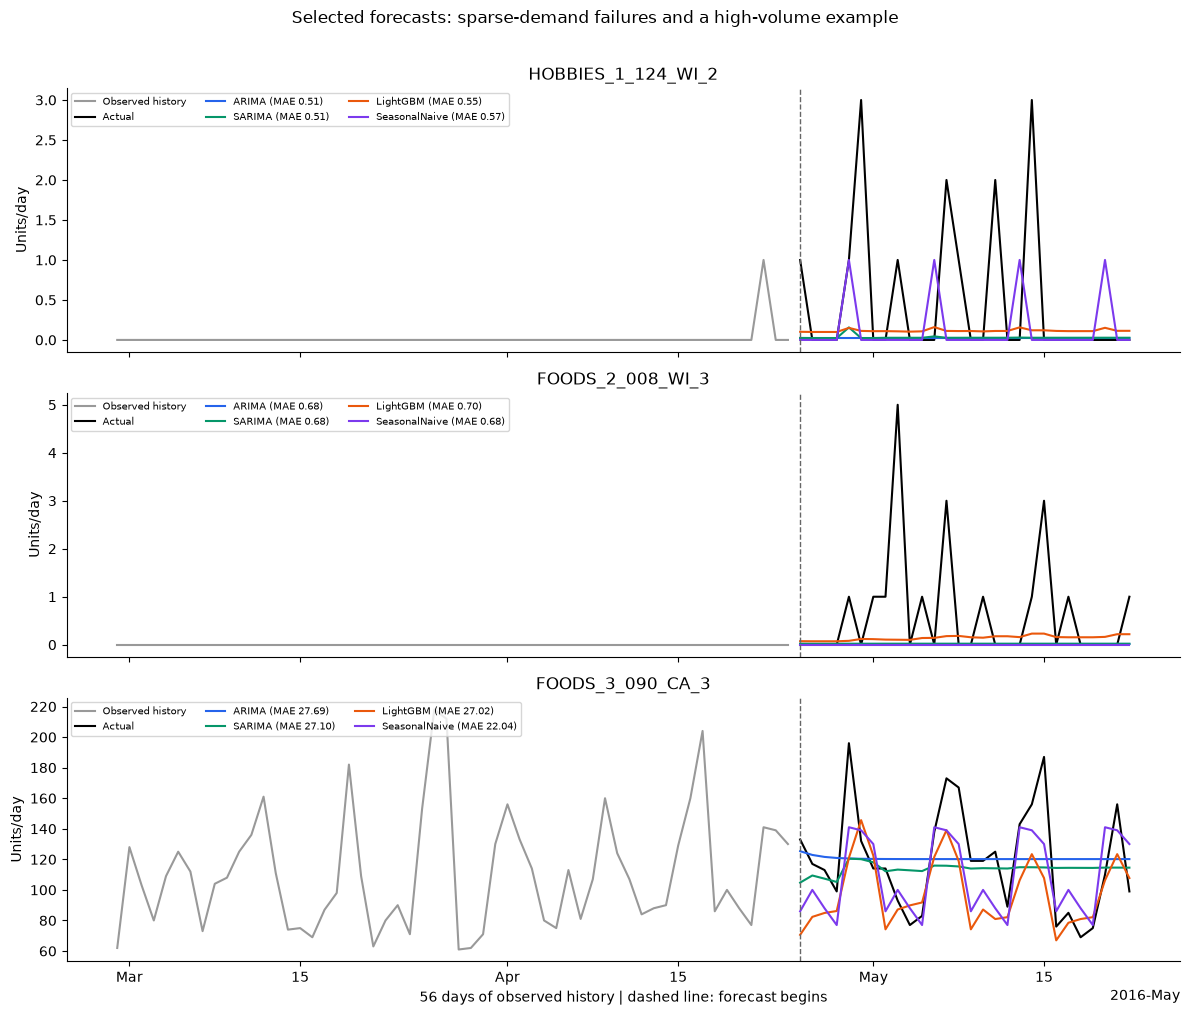

In [23]:
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True)
for ax,position in zip(axes,examples):
    plot_example(ax,position)
locator=mdates.AutoDateLocator(minticks=5,maxticks=8)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[-1].set_xlabel('56 days of observed history | dashed line: forecast begins')
fig.suptitle('Selected forecasts: sparse-demand failures and a high-volume example',y=1.01)
save_figure(data,'comparison_03_forecasts')


## Model summary for the README

In [24]:
def specification_label(specification):
    order=tuple(specification['order'])
    seasonal=tuple(specification['seasonal_order'])
    suffix=f"{seasonal}" if specification['family']=='SARIMA' else ''
    return f"{order}{suffix}; {specification['history_days']} days; trend={specification['trend']}"

model_summary='## Model summary\n\n| Model | Demand group | Selected setting |\n| --- | --- | --- |'
for family in ['ARIMA','SARIMA']:
    for group,specification in selected[family].items():
        model_summary+=f'\n| {family} | {group} | {specification_label(specification)} |'
model_summary+='\n| LightGBM | All | Pooled; 200 trees, 31 leaves, learning rate 0.05 |'
model_summary+='\n| SeasonalNaive | All | Repeat the last seven observed sales values |'
model_summary+='\n\nAll methods forecast every series. Statistical fits are local; LightGBM pools calendar and lag features to correct an eight-week weekday mean.'


In [25]:
tuning_summary=f"""## Development-only tuning

Ten settings vary orders, weekly differencing, and 364/728-day histories.
Screening uses {manifest['screening_series']} stratified series weighted to the full population.
Each family's strongest alternative is confirmed against its original setting
on all 30,490 series in two development windows. Lower mean RMSSE selects settings
separately for regular and intermittent demand, using groups fixed before development.
Groups use 90 days before the first development window; regular sellers have
sales on at least {manifest['identity']['settings']['regular_sales_rate']:.0%} of those days.
Alternative SARIMA uses conditional fitting after differencing, with forecasts
restored to sales units. The local test never selects settings.

![Original, alternative, and selected development scores](reports/figures/comparison_05_tuning.png)
"""


## Evaluation table for the README

In [26]:
readable=comparison.rename(columns={
    'development_rmsse':'Development RMSSE', 'test_rmsse':'Local-test RMSSE',
    'test_mae':'Local-test MAE', 'test_rmse':'Local-test RMSE'})
header='| Model | '+' | '.join(readable.columns)+' |'
separator='| '+' | '.join(['---']*(len(readable.columns)+1))+' |'
rows=['| '+name+' | '+' | '.join(f'{x:.4f}' for x in row)+' |'
      for name,row in readable.iterrows()]
evaluation_table='\n'.join([header,separator,*rows])


In [27]:
start_date=calendar.date.iloc[config['test_cutoff']].strftime('%Y-%m-%d')
end_date=calendar.date.iloc[config['test_cutoff']+27].strftime('%Y-%m-%d')
fit_count=int(convergence.optimized.sum())
converged_count=int(convergence.converged.sum())
constant_count=int(convergence.constant.sum())
coverage=int(scores.loc[scores.phase.eq('local_test'),'rmsse_series'].min())
evaluation_intro=f"""## Evaluation

Three models and a weekly baseline forecast **{len(panel):,} product/store series** for **28 days**.
Two development windows precede the local test, **{start_date} to {end_date}**.
The previously inspected local test makes this a retrospective comparison.
MAE/RMSE cover every series; equal-weight mean RMSSE covers {coverage:,} series with defined training scales.
{converged_count:,}/{fit_count:,} optimized statistical fits converged;
{constant_count:,} constant-history windows receive exact constant forecasts.
"""


## Comparison graphs for the README

In [28]:
graphs="""## Comparison graphs

### Model scores

![Three models and seasonal-naive baseline](reports/figures/comparison_01_models.png)

### Error across the forecast horizon

![MAE by forecast day](reports/figures/comparison_02_horizon.png)
"""


In [29]:
forecast_graph=f"""### Frequent-seller forecasts

{eligible.sum():,} product/store series sold on at least 95% of the 90 days before
the first development window. The examples are the median-volume eligible series
within each category, selected without forecast-period outcomes. All models
forecast these products. Grey lines show 56 days of observed history.

![Frequent sellers: observed history and three-model forecasts](reports/figures/comparison_04_frequent_sellers.png)
"""


In [30]:
forecast_graph+="""
### Sparse-demand and high-volume failure cases

The earlier low-, median-, and high-volume examples remain below.
HOBBIES_1_124_WI_2 had one sale in 728 training days; FOODS_2_008_WI_3 had no sales
in its last 56 training days. Their later recovery remains difficult to predict.
Zero sales alone cannot establish the reason. The same examples are retained across model comparisons.

![Earlier examples and forecast limitations](reports/figures/comparison_03_forecasts.png)
"""


## Final comparison in the README

In [31]:
rmsse_winner=comparison.test_rmsse.idxmin()
mae_winner=comparison.test_mae.idxmin()
rmse_winner=comparison.test_rmse.idxmin()
baseline_rmsse=comparison.loc['SeasonalNaive','test_rmsse']
winner_gain=100*(1-comparison.loc[rmsse_winner,'test_rmsse']/baseline_rmsse)
development_winner=comparison.development_rmsse.idxmin()
if len({rmsse_winner,mae_winner,rmse_winner})==1:
    result_line=f'**{rmsse_winner}** leads local-test mean RMSSE, MAE, and RMSE.'
else:
    result_line=f'**{rmsse_winner}** leads mean RMSSE, **{mae_winner}** MAE, and **{rmse_winner}** RMSE.'


In [32]:
conclusion=f"""## Final comparison

{result_line} Its mean RMSSE is {winner_gain:.1f}% below the weekly baseline.
**{development_winner}** has the lowest average development RMSSE.
All scores cover 30,490 series and common windows. Tuning is a limited search;
individual forecasts still miss spikes and changing demand. The previously
inspected local test supports a retrospective comparison.
"""


In [33]:
change_lines=[]
for family in ['ARIMA','SARIMA']:
    change=improvement.loc[family,'rmsse_improvement_pct']
    if all(specification['id'].endswith('_original') for specification in selected[family].values()):
        change_lines.append(f'{family} retained its original settings; its local-test score is unchanged.')
    else:
        action='lower' if change>=0 else 'higher'
        change_lines.append(f'{family} local-test mean RMSSE is {abs(change):.2f}% {action} than its original setting.')
conclusion+='\n'+' '.join(change_lines)+'\n'


In [34]:
intro="""# Retail Sales Forecasting: ARIMA, SARIMA, and LightGBM

A retail time series study using M5 sales data to compare development-tuned statistical forecasting
with machine learning and a weekly seasonal-naive baseline over a 28-day horizon.
"""
readme='\n\n'.join(section.strip() for section in [
    intro,model_summary,tuning_summary,evaluation_intro,evaluation_table,graphs,forecast_graph,conclusion])+'\n'
(ROOT / 'README.md').write_text(readme)
print('Updated README.md with model summaries, evaluation, and comparison graphs.')


Updated README.md with model summaries, evaluation, and comparison graphs.


All three models beat the weekly baseline; SARIMA tuning improves local-test mean RMSSE by only 0.13%.
LightGBM remains best overall, while the example forecasts still miss daily spikes and demand changes.